# 04 · Hypothesis Tests H2 and H3 (Milestone 3, initial findings)

**Project:** An early-warning system for essential-price shocks across income quintiles in Pakistan (DS4SG, CS/SDP 312/314)

The M2 manuscript (§III-H) promised that **H1–H3 would be tested in Milestone 3**. H1 (can shocks be predicted?) is
tested in notebook 03, next to the models. This notebook tests the two hypotheses behind the "rotating burden" lens:

* **H2 (exchange-rate pass-through):** a fall in the rupee raises the richest quintile's prices more than the poorest's.
* **H3 (rotating burden):** the gap between Q1's and Q5's inflation depends on what is getting more expensive: food
  widens it against the poor, energy narrows it.

**Conventions** (as in M2 and Unit 07): hypotheses are stated about population regression coefficients, tested at the
5% level with the p-value approach, and **one-sided** where M2 stated a direction. Weekly data are autocorrelated, so
every regression uses **Newey–West (HAC) standard errors**. Ordinary standard errors would be too small and the
p-values too optimistic.

**Sample (decision H-1).** The main estimates use the **training period only** (weeks up to 31 December 2024). The
2025–26 weeks stay untouched for model evaluation in M4 and M5, so nothing learned here can leak into the test period.
The full sample is reported as a robustness check.

**Input:** `data/processed/master_features.csv`. **Outputs:** `reports/tables/m3_h2_*.csv`, `m3_h3_*.csv`,
`reports/figures/figB9_fx_passthrough_test.png`, `figB10_rotating_burden_test.png`.

In [1]:
# Setup
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from utils.plot_style import apply_style, GROUP_COLORS, SERIES, INK, INK_SECONDARY, GRID

apply_style()
pd.set_option("display.width", 180)
FIG_DIR, TABLE_DIR = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
TRAIN_END = pd.Timestamp("2024-12-31")
QUINTILES = ["Q1", "Q2", "Q3", "Q4", "Q5"]

df = pd.read_csv(ROOT / "data" / "processed" / "master_features.csv", parse_dates=["week_end"])
week = df[df["group"] == "Combined"].set_index("week_end")        # week-level variables (same for every group)
wide = lambda col: df.pivot(index="week_end", columns="group", values=col)


def hac_ols(y, X, lags):
    # OLS with Newey-West (HAC) standard errors; rows with any missing value are dropped.
    X = sm.add_constant(X)
    m = pd.concat([y, X], axis=1).dropna()
    return sm.OLS(m.iloc[:, 0], m.iloc[:, 1:]).fit(cov_type="HAC", cov_kwds={"maxlags": lags})


def caption(fig, text, y=-0.02):
    fig.text(0.01, y, text, ha="left", va="top", fontsize=9, color=INK_SECONDARY)

## 1. H2: is exchange-rate pass-through larger for the richest quintile?

**Model** (M2 Table 13). For each quintile *g* and week *t*:

$$\Delta^{(8)}\log SPI_{g,t\to t+8} = \alpha_g + \beta^{FX}_g\,\Delta^{(8)}\log FX_{t} + \gamma_1\,\text{own 4-week inflation}_{g,t} + \gamma_2\,\text{motor-fuel inflation}_{t} + \gamma_3\,\text{policy rate}_t + \varepsilon_{g,t}$$

The response is the % change in the group's SPI over the **next** 8 weeks (`target_spi_chg_next8w`). The regressor
of interest is the % depreciation of the rupee over the **past** 8 weeks (`fx_chg_8w`). β<sup>FX</sup> is the
pass-through: by how many percent a group's prices rise in the following two months per 1% fall in the rupee.

* **H0:** β<sup>FX</sup><sub>Q5</sub> = β<sup>FX</sup><sub>Q1</sub>  **H1:** β<sup>FX</sup><sub>Q5</sub> > β<sup>FX</sup><sub>Q1</sub> (one-sided)

**How the difference is tested (decision H-2).** The exchange rate is the same for both groups in a given week, so the
difference between their future inflation, *d*<sub>t</sub> = Δlog SPI<sub>Q5</sub> − Δlog SPI<sub>Q1</sub>, isolates the differential
response. Regressing *d* on the FX change (with the controls) estimates δ = β<sub>Q5</sub> − β<sub>Q1</sub> directly, and its single HAC
standard error already accounts for the correlation between the two groups' errors. Testing H2 means testing δ > 0.

**Details.**
* The 8-week windows overlap from week to week, so errors are autocorrelated up to about 7 lags; HAC uses
  horizon + 2 lags.
* Rows whose future window runs past 31 December 2024 are dropped, so no 2025 price enters the estimate.
* Horizons of 4 and 13 weeks, and a version without controls, are robustness checks.

In [2]:
CONTROLS_H2 = ["infl_motor_fuel_4w", "policy_rate"]


def passthrough(h, end=TRAIN_END, controls=True):
    """Pass-through by quintile and the Q5 - Q1 difference test for horizon h (weeks)."""
    y, own = wide(f"target_spi_chg_next{h}w"), wide("spi_chg_4w")
    idx = week.index[week.index <= end - pd.Timedelta(weeks=h)]      # future window must end by `end`
    base = week.loc[idx, ["fx_chg_8w"] + (CONTROLS_H2 if controls else [])]
    rows = []
    for g in QUINTILES:
        X = pd.concat([base, own.loc[idx, g].rename("own_infl_4w")], axis=1) if controls else base
        m = hac_ols(y.loc[idx, g].rename("y"), X, h + 2)
        lo, hi = m.conf_int().loc["fx_chg_8w"]
        rows.append({"horizon (weeks)": h, "group": g, "beta_FX": m.params["fx_chg_8w"], "SE": m.bse["fx_chg_8w"],
                     "95% CI low": lo, "95% CI high": hi, "n weeks": int(m.nobs)})
    d = (y["Q5"] - y["Q1"]).loc[idx].rename("d")
    Xd = pd.concat([base, (own["Q5"] - own["Q1"]).loc[idx].rename("own_gap_4w")], axis=1) if controls else base
    md_ = hac_ols(d, Xd, h + 2)
    t = md_.tvalues["fx_chg_8w"]
    test = {"horizon (weeks)": h, "controls": controls, "sample end": end.date(),
            "delta = beta_Q5 - beta_Q1": md_.params["fx_chg_8w"], "SE": md_.bse["fx_chg_8w"], "z": t,
            "one-sided p (delta > 0)": stats.norm.sf(t), "n weeks": int(md_.nobs)}
    return pd.DataFrame(rows), test


h2_main, h2_test = passthrough(8)
display(h2_main.round(3))
print(f"H2 test (8 weeks, training period): delta = {h2_test['delta = beta_Q5 - beta_Q1']:.3f} "
      f"(SE {h2_test['SE']:.3f}), z = {h2_test['z']:.2f}, one-sided p = {h2_test['one-sided p (delta > 0)']:.3f}")

,horizon (weeks),group,beta_FX,SE,95% CI low,95% CI high,n weeks
0,8,Q1,0.212,0.109,-0.003,0.426,262
1,8,Q2,0.194,0.142,-0.084,0.471,262
2,8,Q3,0.168,0.136,-0.099,0.435,262
3,8,Q4,0.190,0.123,-0.050,0.431,262
4,8,Q5,0.217,0.123,-0.025,0.459,262


H2 test (8 weeks, training period): delta = 0.037 (SE 0.061), z = 0.60, one-sided p = 0.274


In [3]:
# Robustness: other horizons, no controls, full sample
pt_all, tests = [], []
for h in (4, 8, 13):
    for controls in (True, False):
        for end in (TRAIN_END, week.index.max()):
            pt, test = passthrough(h, end, controls)
            tests.append(test)
            if controls and end == TRAIN_END:
                pt_all.append(pt)
pt_all = pd.concat(pt_all)
h2_tests = pd.DataFrame(tests)
display(h2_tests.round(3))
pt_all.to_csv(TABLE_DIR / "m3_h2_passthrough_by_quintile.csv", index=False)
h2_tests.to_csv(TABLE_DIR / "m3_h2_difference_tests.csv", index=False)

,horizon (weeks),controls,sample end,delta = beta_Q5 - beta_Q1,SE,z,one-sided p (delta > 0),n weeks
0,4,True,2024-12-31,0.021,0.031,0.680,0.248,266
1,4,True,2026-10-01,0.006,0.029,0.195,0.423,358
2,4,False,2024-12-31,0.011,0.026,0.429,0.334,266
3,4,False,2026-10-01,0.009,0.025,0.367,0.357,358
4,8,True,2024-12-31,0.037,0.061,0.601,0.274,262
5,8,True,2026-10-01,0.020,0.059,0.336,0.368,354
6,8,False,2024-12-31,0.008,0.051,0.163,0.435,262
7,8,False,2026-10-01,0.005,0.050,0.103,0.459,354
8,13,True,2024-12-31,0.018,0.054,0.337,0.368,257
9,13,True,2026-10-01,0.020,0.057,0.347,0.364,349


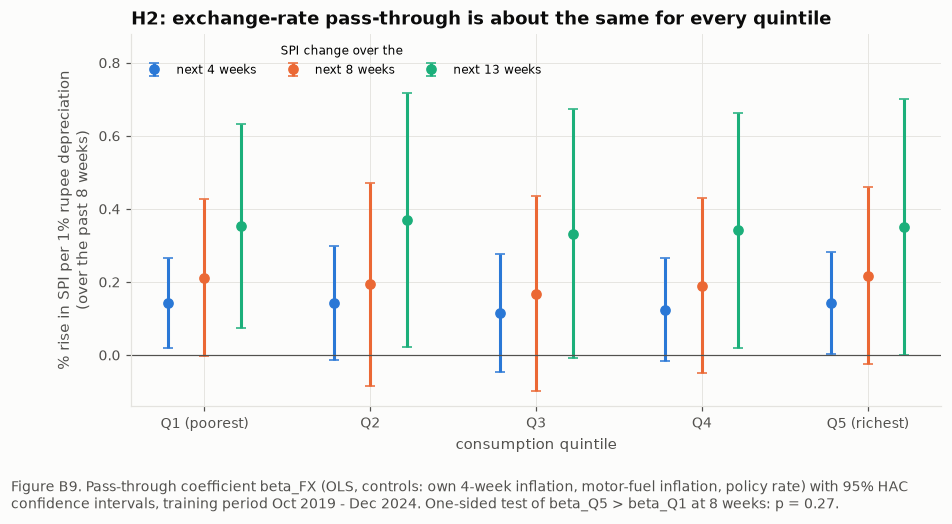

In [4]:
# Figure B9: pass-through by quintile and horizon
fig, ax = plt.subplots(figsize=(9.5, 4.4))
off = {4: -0.22, 8: 0, 13: 0.22}
shade = {4: SERIES[0], 8: SERIES[1], 13: SERIES[2]}
for h in (4, 8, 13):
    s = pt_all[pt_all["horizon (weeks)"] == h]
    x = np.arange(len(QUINTILES)) + off[h]
    ax.errorbar(x, s["beta_FX"], yerr=[s["beta_FX"] - s["95% CI low"], s["95% CI high"] - s["beta_FX"]], fmt="o",
                color=shade[h], ms=6, capsize=3, label=f"next {h} weeks")
ax.axhline(0, color=INK_SECONDARY, lw=0.8)
ax.set_xticks(range(len(QUINTILES)), ["Q1 (poorest)", "Q2", "Q3", "Q4", "Q5 (richest)"])
ax.set_ylabel("% rise in SPI per 1% rupee depreciation\n(over the past 8 weeks)")
ax.set_xlabel("consumption quintile")
ax.legend(title="SPI change over the", fontsize=8, title_fontsize=8, loc="upper left", ncol=3)
ax.set_ylim(top=0.88)
ax.set_title("H2: exchange-rate pass-through is about the same for every quintile")
caption(fig, "Figure B9. Pass-through coefficient beta_FX (OLS, controls: own 4-week inflation, motor-fuel inflation, policy rate) with 95% HAC\n"
             f"confidence intervals, training period Oct 2019 - Dec 2024. One-sided test of beta_Q5 > beta_Q1 at 8 weeks: "
             f"p = {h2_test['one-sided p (delta > 0)']:.2f}.", y=-0.04)
fig.savefig(FIG_DIR / "figB9_fx_passthrough_test.png")
plt.show()

**Decision on H2: fail to reject H0.**
* Over 8 weeks, a 1% rupee depreciation is followed by about a 0.21% rise in Q1's SPI and 0.22% in Q5's. The
  difference δ = 0.04 (SE 0.06) is far from significant (one-sided p ≈ 0.27).
* The same holds at 4 and 13 weeks, without controls and on the full sample (every one-sided p ≥ 0.24).
* The pass-through itself is real and builds over time: about 0.14 after 4 weeks and 0.35 after 13 weeks, for every
  quintile.

**What this changes.** In M2, single-week rupee moves suggested faster pass-through for Q5 (Figure 6 of the M2
draft), but the confidence bands overlapped. With the cumulative 8-week change and the planned controls, the
difference disappears. A falling rupee raises everyone's essential prices by about the same proportion: food imports
(edible oil, pulses, tea) matter for the poor as much as fuel imports do for the rich. **For the early-warning system
this is good news: the exchange-rate signal is equally relevant for every quintile.**

## 2. H3: does the Q1–Q5 gap depend on the source of inflation?

**Model** (M2 Table 13), one row per week:

$$\pi^{Q1}_t - \pi^{Q5}_t = \alpha + \beta_{food}\,\pi^{food}_t + \beta_{energy}\,\pi^{energy}_t + \gamma_1\,\Delta FX_t + \gamma_2\,\text{fuel revision}_t + \text{period dummies} + \varepsilon_t$$

* The response is the gap in weekly inflation between the poorest and the richest quintile (`gap_q1_q5_wow`, in
  percentage points; positive means the poor face more inflation that week).
* π<sup>food</sup> and π<sup>energy</sup> are the weekly price changes of the food and energy items (Combined-weighted, the same for every group).
* The period dummies (2022–23 energy/currency crisis, 2024 disinflation; reference 2019–21) absorb regime-wide
  differences.
* HAC standard errors with 4 lags.

* **H0:** β<sub>food</sub> = β<sub>energy</sub> = 0
* **H1:** β<sub>food</sub> > 0 **and** β<sub>energy</sub> < 0 (food widens the gap against the poor; energy narrows it). Each part is tested
  one-sided.

In [5]:
def gap_regression(regressors, end=TRAIN_END):
    w = week[week.index <= end].copy()
    w["period_2022_23"] = ((w.index.year >= 2022) & (w.index.year <= 2023)).astype(int)
    w["period_2024_26"] = (w.index.year >= 2024).astype(int)
    X = w[regressors + ["fx_wow_pct", "fuel_revision_week", "period_2022_23", "period_2024_26"]].astype(float)
    return hac_ols(w["gap_q1_q5_wow"].rename("gap"), X, 4)


def coef_table(m):
    ci = m.conf_int()
    return pd.DataFrame({"coefficient": m.params, "SE": m.bse, "95% CI low": ci[0], "95% CI high": ci[1],
                         "p (two-sided)": m.pvalues})


h3 = gap_regression(["infl_food_wow", "infl_energy_wow"])
h3_tab = coef_table(h3)
display(h3_tab.round(4))
p_food = stats.norm.sf(h3.tvalues["infl_food_wow"])          # one-sided, H1: beta_food > 0
p_energy = stats.norm.cdf(h3.tvalues["infl_energy_wow"])     # one-sided, H1: beta_energy < 0
print(f"n = {int(h3.nobs)} weeks, R^2 = {h3.rsquared:.3f}")
print(f"beta_food   = {h3.params['infl_food_wow']:+.3f}: one-sided p (> 0) = {p_food:.4f}")
print(f"beta_energy = {h3.params['infl_energy_wow']:+.3f}: one-sided p (< 0) = {p_energy:.4f}")
h3_full = gap_regression(["infl_food_wow", "infl_energy_wow"], end=week.index.max())
print(f"Full sample: beta_food = {h3_full.params['infl_food_wow']:+.3f} (one-sided p = {stats.norm.sf(h3_full.tvalues['infl_food_wow']):.4f}), "
      f"beta_energy = {h3_full.params['infl_energy_wow']:+.3f} (one-sided p for < 0 = {stats.norm.cdf(h3_full.tvalues['infl_energy_wow']):.3f})")
h3_tab.to_csv(TABLE_DIR / "m3_h3_gap_regression.csv")

,coefficient,SE,95% CI low,95% CI high,p (two-sided)
const,0.0357,0.0487,-0.0599,0.1312,0.4644
infl_food_wow,0.1216,0.0439,0.0357,0.2076,0.0055
infl_energy_wow,0.0430,0.0304,-0.0165,0.1026,0.1569
fx_wow_pct,-0.0645,0.0388,-0.1406,0.0116,0.0966
fuel_revision_week,-0.2137,0.1007,-0.4111,-0.0163,0.0338
period_2022_23,-0.1179,0.0860,-0.2865,0.0506,0.1702
period_2024_26,0.0326,0.0814,-0.1270,0.1922,0.6890


n = 277 weeks, R^2 = 0.161
beta_food   = +0.122: one-sided p (> 0) = 0.0028
beta_energy = +0.043: one-sided p (< 0) = 0.9215
Full sample: beta_food = +0.167 (one-sided p = 0.0003), beta_energy = +0.035 (one-sided p for < 0 = 0.892)


**Why might energy not narrow the gap?** PBS's "energy" category mixes items that weigh very differently across the
quintiles:
* **utility tariffs:** the "electricity for Q1" and "gas for Q1" charges, i.e. the lowest consumption slabs, which
  weigh heavily in the poorest basket;
* **motor fuel** (petrol, diesel), which weighs more for richer households;
* **market energy** (LPG, firewood).

The next cell is an **exploratory** follow-up, not part of the pre-stated H3. It splits food into staples and
perishables and energy into those three components (the same split as the M2 features, decision F4).

In [6]:
split = gap_regression(["infl_staples_wow", "infl_perishables_wow", "infl_utilities_wow", "infl_motor_fuel_wow",
                        "infl_market_energy_wow"])
split_tab = coef_table(split)
display(split_tab.round(4))
print(f"R^2 rises from {h3.rsquared:.2f} (food + energy) to {split.rsquared:.2f} (five components)")
split_tab.to_csv(TABLE_DIR / "m3_h3_components_exploratory.csv")

,coefficient,SE,95% CI low,95% CI high,p (two-sided)
const,0.0269,0.0500,-0.0712,0.1249,0.5913
infl_staples_wow,0.1270,0.1034,-0.0757,0.3298,0.2195
infl_perishables_wow,0.0272,0.0073,0.0130,0.0415,0.0002
infl_utilities_wow,0.0345,0.0207,-0.0061,0.0752,0.0954
infl_motor_fuel_wow,-0.0706,0.0072,-0.0847,-0.0565,0.0000
infl_market_energy_wow,-0.0279,0.0118,-0.0510,-0.0048,0.0181
fx_wow_pct,-0.0324,0.0282,-0.0877,0.0229,0.2509
fuel_revision_week,-0.0961,0.0844,-0.2615,0.0693,0.2547
period_2022_23,-0.1256,0.0651,-0.2532,0.0019,0.0536
period_2024_26,-0.0120,0.0683,-0.1459,0.1218,0.8603


R^2 rises from 0.16 (food + energy) to 0.38 (five components)


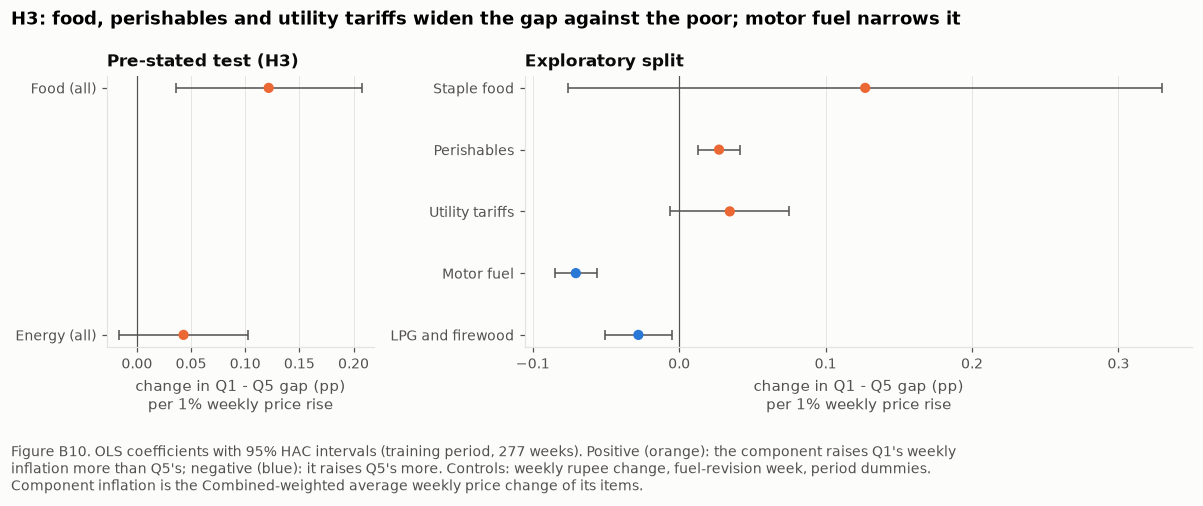

In [7]:
# Figure B10: what widens and what narrows the poor-rich inflation gap
labels = {"infl_food_wow": "Food (all)", "infl_energy_wow": "Energy (all)", "infl_staples_wow": "Staple food",
          "infl_perishables_wow": "Perishables", "infl_utilities_wow": "Utility tariffs",
          "infl_motor_fuel_wow": "Motor fuel", "infl_market_energy_wow": "LPG and firewood"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), sharex=False, gridspec_kw={"width_ratios": [2, 5]})
for ax, tab, title in [(a1, h3_tab, "Pre-stated test (H3)"), (a2, split_tab, "Exploratory split")]:
    keys = [k for k in labels if k in tab.index]
    t = tab.loc[keys]
    yy = np.arange(len(keys))[::-1]
    col = [SERIES[1] if v > 0 else SERIES[0] for v in t["coefficient"]]
    ax.errorbar(t["coefficient"], yy, xerr=[t["coefficient"] - t["95% CI low"], t["95% CI high"] - t["coefficient"]],
                fmt="none", ecolor=INK_SECONDARY, elinewidth=1, capsize=3)
    ax.scatter(t["coefficient"], yy, color=col, s=45, zorder=3)
    ax.axvline(0, color=INK_SECONDARY, lw=0.8)
    ax.set_yticks(yy, [labels[k] for k in keys])
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("change in Q1 - Q5 gap (pp)\nper 1% weekly price rise")
    ax.grid(axis="y", visible=False)
fig.suptitle("H3: food, perishables and utility tariffs widen the gap against the poor; motor fuel narrows it",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
caption(fig, "Figure B10. OLS coefficients with 95% HAC intervals (training period, 277 weeks). Positive (orange): the component raises Q1's weekly\n"
             "inflation more than Q5's; negative (blue): it raises Q5's more. Controls: weekly rupee change, fuel-revision week, period dummies.\n"
             "Component inflation is the Combined-weighted average weekly price change of its items.", y=-0.03)
fig.savefig(FIG_DIR / "figB10_rotating_burden_test.png")
plt.show()

**Decision on H3: partly supported.**
* **Food part: reject H0.** A 1% rise in food prices in a week raises Q1's inflation by about 0.12 percentage points
  more than Q5's (one-sided p ≈ 0.003; full sample 0.17, p < 0.001). Food shocks widen the gap against the poor.
* **Energy part: fail to reject H0.** The energy coefficient is small and *positive* (+0.04, one-sided p ≈ 0.92 for
  "< 0"). Energy as a whole does not shift the burden towards the rich.
* **The exploratory split explains why** (R² rises from 0.16 to 0.38):
  * **motor fuel** (−0.07, p < 0.001) and LPG/firewood (−0.03, p ≈ 0.02) do narrow the gap: they hit the rich harder;
  * **utility tariffs** (+0.03, p ≈ 0.10) and **perishables** (+0.03, p < 0.001) widen it.

  Inside "energy" the two effects cancel out.
* **Refined lens for the manuscript:** the burden rotates between **motor-fuel shocks (heavier on the rich)** and
  **food and utility-tariff shocks (heavier on the poor)**. This matches the M2 variance decomposition: utility tariffs
  cause about 61% of Q1's weekly variability. It is also why the M3 models' failure to anticipate tariff increases
  (notebook 03, §8) matters most for the poorest quintile.
* Because the split was chosen after seeing the H3 result, it is a hypothesis for M4, not a confirmed finding.

## 3. Summary

| Hypothesis | Test | Result | Decision (5%) |
|---|---|---|---|
| H2: pass-through larger for Q5 | HAC difference regression, δ = β<sub>Q5</sub> − β<sub>Q1</sub> > 0 | δ = 0.04, p = 0.27 (8 weeks) | fail to reject H0 |
| H3 food: food widens the gap | one-sided t-test, β<sub>food</sub> > 0 | β = 0.12, p = 0.003 | reject H0 |
| H3 energy: energy narrows the gap | one-sided t-test, β<sub>energy</sub> < 0 | β = +0.04, p = 0.92 | fail to reject H0 |

H1 is tested in notebook 03 (§10).